# Chapitre 7 - Cours 2 : goulots mémoire, représentations numériques et quantification

Le livre consacre une longue section, *Memory Bottlenecks*, à la question qui conditionne
toutes les techniques de finetuning modernes : **combien de mémoire faut-il**, et
pourquoi bien plus pour entraîner que pour servir un modèle ? Ce notebook en reprend les
sous-sections *Backpropagation and Trainable Parameters*, *Memory Math*, *Numerical
Representations* et *Quantization* (avec *Inference quantization* et *Training
quantization*), en remplaçant les ordres de grandeur par des calculs et des **mesures**
sur le GPU :

1. rétropropagation et paramètres entraînables (un réseau à trois paramètres, à la main) ;
2. le calcul de mémoire : inférence, entraînement, activations (calculateur du module) ;
3. mesures réelles de la mémoire GPU d'un pas d'entraînement (GPT-2, Qwen2.5-0.5B) et
   gradient checkpointing ;
4. représentations numériques : FP32, TF32, FP16, BF16, FP8, INT8, INT4 (bits, plages,
   précision, erreurs d'arrondi, précision mixte) ;
5. quantification : absmax, zéro-point, par groupe (écrites à la main) ;
6. quantifier de vrais poids (Qwen2.5-0.5B) : distributions, NF4, erreurs ;
7. impact sur la perplexité, et vraie quantification avec bitsandbytes ;
8. entraîner en basse précision : PTQ, QAT et précision mixte.

In [1]:
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message=".*MatMul8bitLt.*")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9

## 1. Rétropropagation et paramètres entraînables (section *Backpropagation and Trainable Parameters*)

**Le problème.** À l'inférence, un paramètre n'occupe que sa propre place. À
l'entraînement, chaque paramètre **entraînable** traîne avec lui des valeurs
supplémentaires. Pour comprendre lesquelles, déroulons un pas d'entraînement sur le plus
petit réseau possible, comme la figure 7-4 du livre : trois paramètres $w_1, w_2, w_3$ et
une non-linéarité $\sigma$ (sigmoïde) :
$$h = w_1 x + w_2, \qquad a = \sigma(h), \qquad \hat y = w_3\, a, \qquad L = (\hat y - y)^2.$$

- **Passe avant** : on calcule $h, a, \hat y, L$ et l'on **garde** $x, h, a$ en mémoire
  (ce sont les **activations**, nécessaires à la passe arrière).
- **Passe arrière** : la règle de la chaîne donne un **gradient** par paramètre
  entraînable : $\partial L/\partial \hat y = 2(\hat y - y)$, puis
  $\partial L/\partial w_3 = 2(\hat y - y)\,a$,
  $\partial L/\partial w_1 = 2(\hat y - y)\,w_3\,\sigma'(h)\,x$ et
  $\partial L/\partial w_2 = 2(\hat y - y)\,w_3\,\sigma'(h)$, avec $\sigma'(h) = a(1-a)$.
- **Mise à jour** par l'optimiseur. **Adam** garde, pour chaque paramètre, deux moyennes
  mobiles : $m \leftarrow \beta_1 m + (1-\beta_1) g$ (moment d'ordre 1) et
  $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ (moment d'ordre 2), puis
  $w \leftarrow w - \eta\, \hat m / (\sqrt{\hat v} + \epsilon)$.

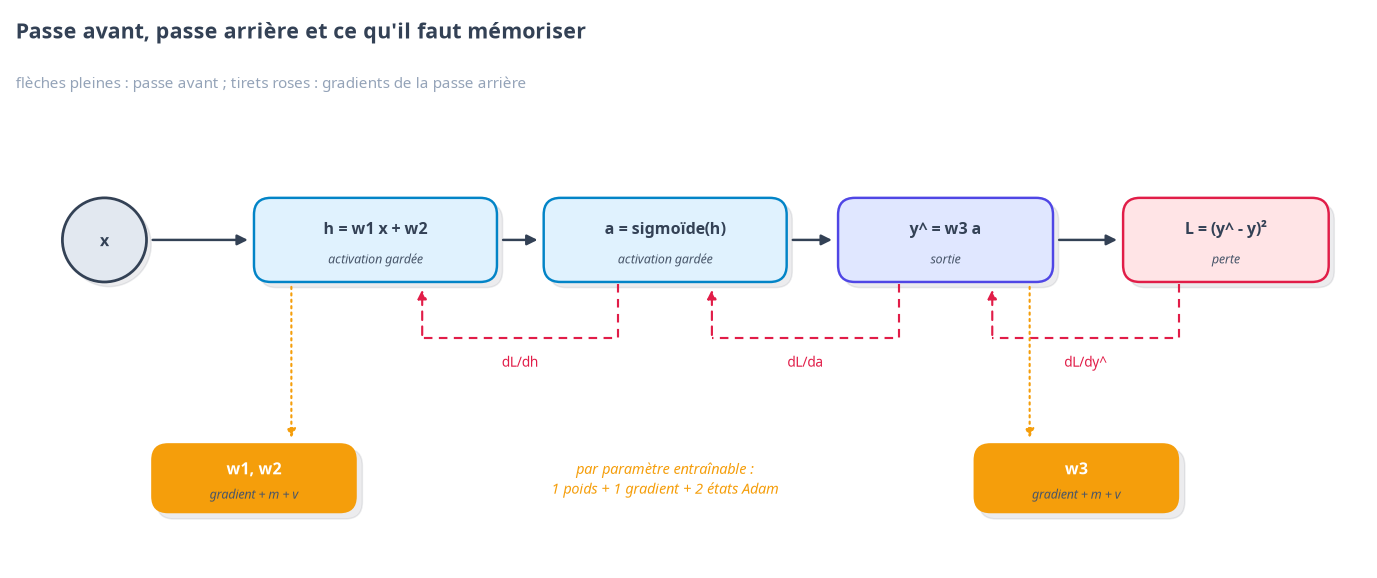

In [2]:
d = Diagram(14.5, 5.0, title="Passe avant, passe arrière et ce qu'il faut mémoriser",
            subtitle="flèches pleines : passe avant ; tirets roses : gradients de la passe arrière")
Y = 3.5
d.box("x", 1.0, Y, "x", color=SLATE, kind="circle", w=0.9)
d.box("h", 3.9, Y, "h = w1 x + w2", sub="activation gardée", color=SKY, w=2.6)
d.box("a", 7.0, Y, "a = sigmoïde(h)", sub="activation gardée", color=SKY, w=2.6)
d.box("y", 10.0, Y, "y^ = w3 a", sub="sortie", color=INDIGO, w=2.3)
d.box("L", 13.0, Y, "L = (y^ - y)²", sub="perte", color=ROSE, w=2.2)
for a_, b_ in [("x", "h"), ("h", "a"), ("a", "y"), ("y", "L")]:
    d.arrow(a_, b_)
for x1, x2, lab in [(13.0, 10.0, "dL/dy^"), (10.0, 7.0, "dL/da"), (7.0, 3.9, "dL/dh")]:
    d.line([(x1 - 0.5, Y - 0.47), (x1 - 0.5, Y - 1.05), (x2 + 0.5, Y - 1.05), (x2 + 0.5, Y - 0.5)], color=ROSE, style="dashed", lw=1.4)
    d.note((x1 + x2) / 2, Y - 1.3, lab, color=ROSE, fontsize=9, style="normal")
d.box("w12", 2.6, 0.95, "w1, w2", sub="gradient + m + v", color=AMBER, kind="tag", w=2.2, h=0.75)
d.box("w3", 11.4, 0.95, "w3", sub="gradient + m + v", color=AMBER, kind="tag", w=2.2, h=0.75)
d.line([(3.0, Y - 0.47), (3.0, 1.35)], color=AMBER, style="dotted", lw=1.4)
d.line([(10.9, Y - 0.47), (10.9, 1.35)], color=AMBER, style="dotted", lw=1.4)
d.note(7.0, 0.95, "par paramètre entraînable :\n1 poids + 1 gradient + 2 états Adam", color=AMBER, fontsize=9.5)
d.show()

In [3]:
sig = lambda z: 1 / (1 + np.exp(-z))


def forward(w, x, y):
    h = w[0] * x + w[1]; a = sig(h); yh = w[2] * a
    return (yh - y) ** 2, (h, a, yh)


def backward(w, x, y):
    L, (h, a, yh) = forward(w, x, y)
    dy = 2 * (yh - y); dh = dy * w[2] * a * (1 - a)
    return np.array([dh * x, dh, dy * a])


w = np.array([0.5, -0.3, 1.2]); x, y = 2.0, 1.5
g = backward(w, x, y)
eps = 1e-6
g_num = np.array([(forward(w + eps * np.eye(3)[i], x, y)[0] - forward(w - eps * np.eye(3)[i], x, y)[0]) / (2 * eps)
                  for i in range(3)])
# un pas d'Adam (beta1 = 0.9, beta2 = 0.999, lr = 0.1)
m = 0.1 * g; v = 0.001 * g ** 2
m_hat, v_hat = m / (1 - 0.9), v / (1 - 0.999)
w_new = w - 0.1 * m_hat / (np.sqrt(v_hat) + 1e-8)
pd.DataFrame({"poids w": w, "gradient (règle de la chaîne)": g, "gradient (diff. finies)": g_num,
              "état Adam m": m, "état Adam v": v, "w après 1 pas": w_new},
             index=["w1", "w2", "w3"]).round(5)

,poids w,gradient (règle de la chaîne),gradient (diff. finies),état Adam m,état Adam v,w après 1 pas
w1,0.5,-0.74301,-0.74301,-0.07430,0.00055,0.6
w2,-0.3,-0.37151,-0.37151,-0.03715,0.00014,-0.2
w3,1.2,-0.93302,-0.93302,-0.09330,0.00087,1.3


Les gradients analytiques coïncident avec les différences finies. Au premier pas, Adam
déplace chaque poids d'environ $\eta$ dans la direction opposée au gradient (le rapport
$\hat m/\sqrt{\hat v}$ vaut $\pm 1$), quelle que soit l'échelle du gradient. Le bilan
mémoire est le cœur du chapitre : **par paramètre entraînable**, il faut stocker le poids,
son gradient et (avec Adam) deux états, soit quatre valeurs au lieu d'une ; un paramètre
**gelé** ne coûte que son poids. Moins de paramètres entraînables, c'est l'idée de PEFT
(cours 3).

> **À retenir.** Inférence = passe avant seule. Entraînement = passe avant (activations
> gardées) + passe arrière (un gradient par paramètre entraînable) + optimiseur (0 état
> pour SGD, 1 pour le momentum, 2 pour Adam).

## 2. Le calcul de mémoire (section *Memory Math*)

**Inférence.** Avec $N$ paramètres de $M$ octets chacun, les poids occupent $N \times M$.
Il faut y ajouter les activations et le cache clé-valeur (chapitre 9) ; le livre propose
la règle empirique de 20 % :
$$\text{mémoire}_{\text{inférence}} \approx N \times M \times 1{,}2.$$
Exemple du livre : 13 milliards de paramètres en 16 bits, $26 \text{ Go} \times 1{,}2 = 31{,}2$ Go.

**Entraînement.**
$$\text{mémoire}_{\text{entraînement}} = \text{poids} + \text{activations} + \text{gradients} + \text{états de l'optimiseur}.$$
Le livre compte, pour Adam, trois valeurs de 2 octets par paramètre entraînable (un
gradient et deux états) : un 13 B entièrement entraîné demande $13 \cdot 10^9 \times 3 \times 2 = 78$ Go
en plus des poids ; avec seulement 1 milliard de paramètres entraînables, 6 Go.

En pratique, la recette de **précision mixte** la plus répandue (poids et gradients en
16 bits, copie « maîtresse » des poids et états d'Adam en 32 bits) coûte
$2 + 2 + 4 + 4 + 4 = 16$ octets par paramètre entraînable. `c7.training_memory` implémente
les deux conventions (`recipe="livre"` et `recipe="mixte"`).

In [4]:
rows = []
for name, spec in c7.MODEL_SPECS.items():
    N = spec.n_params
    rows.append({"modèle": name,
                 "inférence 16 bits (x1,2)": c7.inference_memory(N, 2) / GB,
                 "LoRA (1 % entraînable, livre)": c7.training_memory(N, 0.01 * N)["total"] / GB,
                 "finetuning complet (livre)": c7.training_memory(N)["total"] / GB,
                 "finetuning complet (précision mixte)": c7.training_memory(N, recipe="mixte")["total"] / GB})
mem = pd.DataFrame(rows).set_index("modèle")
mem.round(1)

,"inférence 16 bits (x1,2)","LoRA (1 % entraînable, livre)",finetuning complet (livre),finetuning complet (précision mixte)
modèle,,,,
GPT-2 (124M),0.3,0.3,1.0,2.0
Qwen2.5-0.5B,1.2,1.0,4.0,7.9
Qwen2.5-1.5B,3.7,3.2,12.3,24.6
Llama 2-7B,16.2,13.9,53.9,107.8
Llama 2-13B,31.2,26.8,104.0,208.0
Llama 2-70B,165.6,142.1,552.0,1104.0
GPT-3 (175B),420.0,360.5,1400.0,2800.0


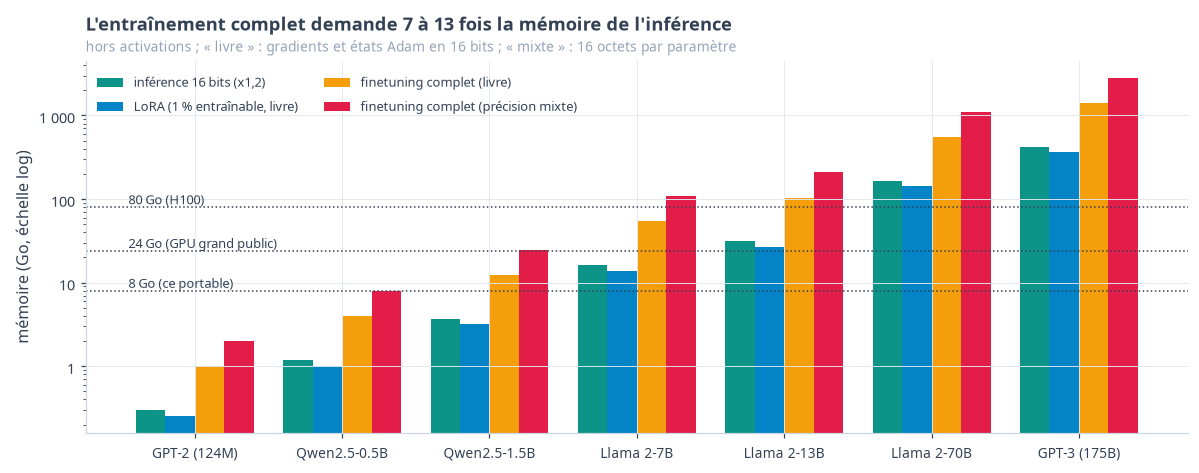

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.4))
cols = mem.columns
xk = np.arange(len(mem))
for j, (c, col) in enumerate(zip(cols, [TEAL, SKY, AMBER, ROSE])):
    ax.bar(xk + (j - 1.5) * 0.2, mem[c], 0.2, color=col, label=c)
ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "y")
for cap, lab in [(8, "8 Go (ce portable)"), (24, "24 Go (GPU grand public)"), (80, "80 Go (H100)")]:
    ax.axhline(cap, color=SLATE, ls=":", lw=1)
    ax.text(-0.45, cap * 1.08, lab, fontsize=8.5, color=SLATE, ha="left")
ax.set_xticks(xk, mem.index, fontsize=9); ax.set_ylabel("mémoire (Go, échelle log)")
ax.legend(ncol=2, fontsize=8.5, loc="upper left", bbox_to_anchor=(0.0, 1.0))
c7.title_sub(ax, "L'entraînement complet demande 7 à 13 fois la mémoire de l'inférence",
             "hors activations ; « livre » : gradients et états Adam en 16 bits ; « mixte » : 16 octets par paramètre")
plt.tight_layout(); plt.show()

Sur ce GPU de 8 Go, l'inférence est possible jusqu'à environ 3 milliards de paramètres en
16 bits ; le finetuning **complet** ne passe que pour les modèles de quelques centaines de
millions de paramètres. L'exemple du livre se retrouve : un 7 B en finetuning complet
demande $14 + 42 = 56$ Go selon sa convention, hors de portée des GPU grand public.

**Les activations.** Elles croissent linéairement avec la taille du lot $b$ et (au moins)
linéairement avec la longueur $s$ de la séquence. Korthikanti et al. (2022), dont le livre
reproduit la figure 7-5, donnent pour un bloc transformer en 16 bits de dimension $h$ à $a$
têtes :
$$\text{activations par couche} \approx s\,b\,h\left(34 + \frac{5\,a\,s}{h}\right) \text{ octets}.$$
Le terme en $s^2$ vient des matrices d'attention. Le **gradient checkpointing** (ou
recalcul des activations) ne garde que l'entrée de chaque bloc ($2sbh$ octets) et
recalcule le reste pendant la passe arrière : moins de mémoire, plus de calcul.

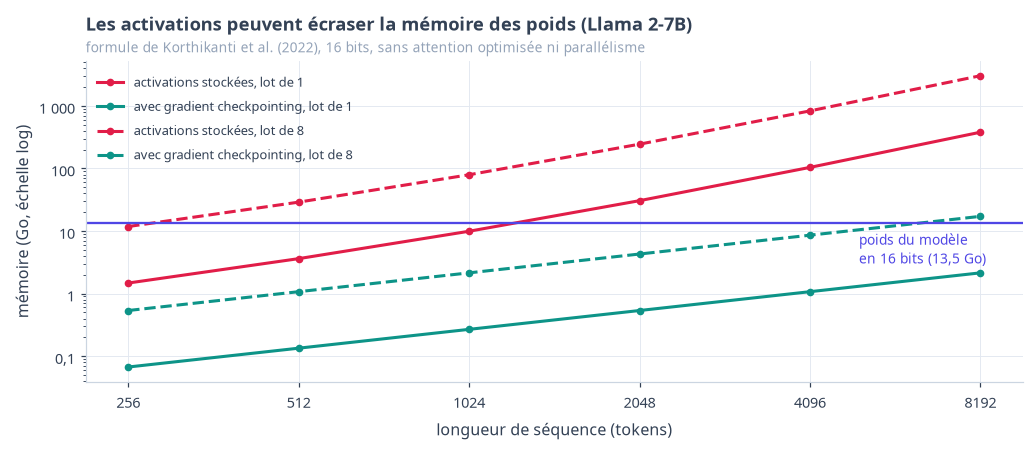

In [6]:
spec = c7.MODEL_SPECS["Llama 2-7B"]
seqs = np.array([256, 512, 1024, 2048, 4096, 8192])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for b, ls in [(1, "-"), (8, "--")]:
    ax.plot(seqs, [c7.activation_memory(spec, s, b) / GB for s in seqs], ls, color=ROSE, marker="o", ms=4,
            label=f"activations stockées, lot de {b}")
    ax.plot(seqs, [c7.activation_memory(spec, s, b, checkpointing="complet") / GB for s in seqs], ls, color=TEAL,
            marker="o", ms=4, label=f"avec gradient checkpointing, lot de {b}")
ax.axhline(spec.n_params * 2 / GB, color=INDIGO, lw=1.5)
ax.text(5000, spec.n_params * 2 / GB / 1.3, "poids du modèle\nen 16 bits (13,5 Go)", color=INDIGO, fontsize=9, va="top")
ax.set_xscale("log", base=2); ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "y")
ax.set_xticks(seqs, [str(s) for s in seqs]); ax.set_xlabel("longueur de séquence (tokens)")
ax.set_ylabel("mémoire (Go, échelle log)"); ax.legend(fontsize=8.5, loc="upper left")
c7.title_sub(ax, "Les activations peuvent écraser la mémoire des poids (Llama 2-7B)",
             "formule de Korthikanti et al. (2022), 16 bits, sans attention optimisée ni parallélisme")
plt.tight_layout(); plt.show()

Dès 2 048 tokens avec un lot de 8, les activations dépassent largement les poids. (Les
noyaux d'attention modernes comme FlashAttention ne matérialisent pas la matrice
$s \times s$ et suppriment l'essentiel du terme quadratique ; l'ordre de grandeur linéaire
reste.)

> **À retenir.** Inférence : $\approx 1{,}2\,N M$. Entraînement : poids + activations +
> (gradient + états) par paramètre **entraînable**. Les activations dépendent du lot et de
> la séquence, et peuvent dominer ; le gradient checkpointing les échange contre du calcul.

## 3. Mesures réelles sur le GPU (section *Memory Math*)

Vérifions ces formules avec `torch.cuda.memory_allocated`, qui compte les octets
réellement alloués par PyTorch. `c7.measure_train_step` effectue deux pas d'entraînement
et isole : les **poids** (avant tout), les **activations** gardées après la passe avant,
les **gradients** après la passe arrière et les **états de l'optimiseur** qui persistent
entre les pas.

**Expérience 1 : GPT-2 (124 M) en FP32**, lot de 2 séquences de 256 tokens, avec trois
configurations : Adam sur tous les poids, SGD sans momentum sur tous les poids, et Adam
sur la dernière couche seulement (finetuning **partiel**).

In [7]:
texte = " ".join(c7.TEXTES_EVAL) * 6


def gpt2_batch(tok, b=2, s=256, device="cuda"):
    ids = tok(texte, return_tensors="pt", truncation=True, max_length=s)["input_ids"].repeat(b, 1).to(device)
    return {"input_ids": ids, "labels": ids}


def run_gpt2(config):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained("gpt2")
    model = AutoModelForCausalLM.from_pretrained("gpt2", dtype=torch.float32).cuda()
    if config == "partiel (dernier bloc, Adam)":
        for n_, p in model.named_parameters():
            p.requires_grad_(n_.startswith("transformer.h.11."))
    opt = (lambda ps: torch.optim.SGD(ps, lr=1e-4)) if config.startswith("SGD") else (lambda ps: torch.optim.Adam(ps, lr=1e-5))
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    r = c7.measure_train_step(model, gpt2_batch(tok), opt)
    r["paramètres entraînables"] = n_train
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


llm.free_gpu()
configs = ["complet (Adam)", "SGD complet", "partiel (dernier bloc, Adam)"]
meas = {c: c7.gpu_retry(run_gpt2, c) for c in configs}
c7.log_vram("nb2 gpt2")
N2 = 124.4e6
pred = {"complet (Adam)": (4 * N2, 4 * N2, 8 * N2), "SGD complet": (4 * N2, 4 * N2, 0),
        "partiel (dernier bloc, Adam)": (4 * N2, 4 * meas["partiel (dernier bloc, Adam)"]["paramètres entraînables"],
                                         8 * meas["partiel (dernier bloc, Adam)"]["paramètres entraînables"])}
OPT = "états de l'optimiseur"
tab = pd.DataFrame({c: {"entraînables (M)": meas[c]["paramètres entraînables"] / 1e6,
                        "poids mesurés / prévus (Go)": f"{meas[c]['poids'] / GB:.2f} / {pred[c][0] / GB:.2f}",
                        "gradients mesurés / prévus": f"{meas[c]['gradients'] / GB:.2f} / {pred[c][1] / GB:.2f}",
                        "états optim. mesurés / prévus": f"{meas[c][OPT] / GB:.2f} / {pred[c][2] / GB:.2f}",
                        "activations mesurées (Go)": round(meas[c]["activations"] / GB, 2),
                        "pic (Go)": round(meas[c]["pic"] / GB, 2)} for c in configs}).T
tab

,entraînables (M),poids mesurés / prévus (Go),gradients mesurés / prévus,états optim. mesurés / prévus,activations mesurées (Go),pic (Go)
complet (Adam),124.439808,0.50 / 0.50,0.50 / 0.50,1.02 / 1.00,0.78,2.4
SGD complet,124.439808,0.52 / 0.50,0.50 / 0.50,0.00 / 0.00,0.77,1.39
"partiel (dernier bloc, Adam)",7.087872,0.52 / 0.50,0.03 / 0.03,0.06 / 0.06,0.26,0.93


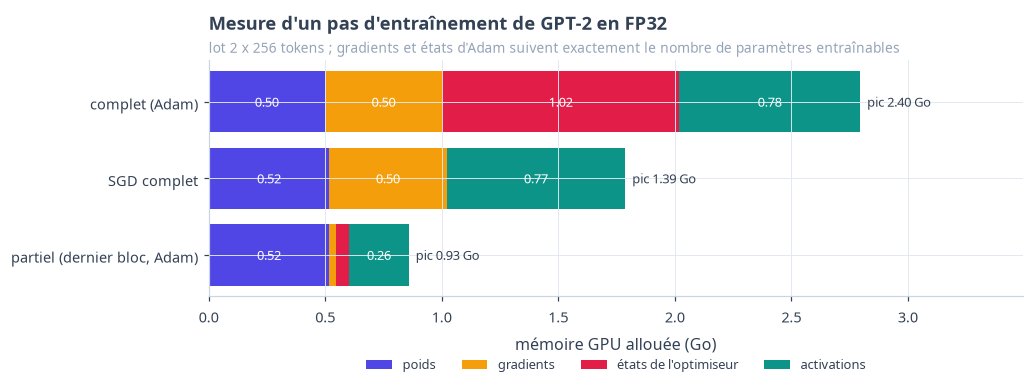

In [8]:
parts = ["poids", "gradients", "états de l'optimiseur", "activations"]
colors = [INDIGO, AMBER, ROSE, TEAL]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
left = np.zeros(len(configs))
for p_, col in zip(parts, colors):
    vals = np.array([max(meas[c][p_], 0) / GB for c in configs])
    ax.barh(configs, vals, left=left, color=col, label=p_)
    for i, v in enumerate(vals):
        if v > 0.12:
            ax.text(left[i] + v / 2, i, f"{v:.2f}", ha="center", va="center", color="white", fontsize=8.5)
    left += vals
for i, c in enumerate(configs):
    ax.text(left[i] + 0.03, i, f"pic {meas[c]['pic'] / GB:.2f} Go", va="center", fontsize=8.5, color=SLATE)
ax.invert_yaxis(); ax.set_xlabel("mémoire GPU allouée (Go)"); ax.set_xlim(0, left.max() * 1.25)
ax.legend(ncol=4, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
c7.title_sub(ax, "Mesure d'un pas d'entraînement de GPT-2 en FP32",
             "lot 2 x 256 tokens ; gradients et états d'Adam suivent exactement le nombre de paramètres entraînables")
plt.tight_layout(); plt.show()

Les poids, gradients et états mesurés retombent sur les prévisions à quelques pour cent
près ($124 \cdot 10^6 \times 4$ octets $\approx 0{,}5$ Go chacun, et le double pour les deux
états d'Adam). Avec SGD sans momentum, les états disparaissent ; en ne laissant que le
dernier bloc entraînable (7 M paramètres sur 124 M), gradients et états fondent, mais les
activations restent du même ordre : il faut encore propager le gradient jusqu'à ce bloc,
et la couche de sortie (logits sur 50 257 tokens) en consomme une bonne partie.
Notez que la somme des barres dépasse le pic : les activations sont libérées au fur et à
mesure que la passe arrière crée les gradients, les deux ne coexistent jamais en totalité.

**Expérience 2 : Qwen2.5-0.5B en BF16.** Un finetuning complet avec Adam demanderait
$0{,}49 \cdot 10^9 \times 8$ octets $\approx 4$ Go pour poids, gradients et états, sans
compter les activations : on reste sous notre budget en mesurant l'inférence et un pas de
finetuning **LoRA** (cours 3), où seuls 0,9 % des paramètres sont entraînables.

In [9]:
from peft import LoraConfig, get_peft_model


def run_qwen(seq, batch, lora=True, checkpointing=False):
    tok, model = c7.load_fresh(llm.SMALL)
    model.config.use_cache = False
    if checkpointing:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    if lora:
        model = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, target_modules="all-linear", task_type="CAUSAL_LM"))
    ids = tok(texte, return_tensors="pt")["input_ids"][:, :seq].repeat(batch, 1).cuda()
    r = c7.measure_train_step(model, {"input_ids": ids, "labels": ids}, lambda ps: torch.optim.AdamW(ps, lr=1e-4))
    r["entraînables"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


def run_qwen_inference(seq, batch):
    tok, model = c7.load_fresh(llm.SMALL)
    ids = tok(texte, return_tensors="pt")["input_ids"][:, :seq].repeat(batch, 1).cuda()
    torch.cuda.synchronize(); base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        model(ids)
    r = {"poids": base, "pic": torch.cuda.max_memory_allocated()}
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


inf = c7.gpu_retry(run_qwen_inference, 384, 1)
lo = c7.gpu_retry(run_qwen, 384, 1)
c7.log_vram("nb2 qwen lora")
V = 151936
logits_bytes = 384 * V * 4  # logits convertis en FP32 pour la perte
pd.DataFrame({"inférence (1 x 384 tokens)": [inf["poids"] / GB, np.nan, np.nan, inf["pic"] / GB],
              "pas LoRA r=8 (1 x 384 tokens)": [lo["poids"] / GB, lo["gradients"] / GB, lo["états de l'optimiseur"] / GB, lo["pic"] / GB]},
             index=["poids (Go)", "gradients (Go)", "états Adam (Go)", "pic (Go)"]).round(3).T.assign(
    **{"entraînables": [np.nan, f"{lo['entraînables'] / 1e6:.1f} M"]})

,poids (Go),gradients (Go),états Adam (Go),pic (Go),entraînables
inférence (1 x 384 tokens),1.013,NaN,NaN,1.136,NaN
pas LoRA r=8 (1 x 384 tokens),1.031,0.018,0.035,2.556,4.4 M


Les poids BF16 pèsent $\approx 1$ Go ($494 \cdot 10^6 \times 2$ octets ; les embeddings sont
partagés avec la couche de sortie). Avec LoRA, gradients et états ne pèsent que quelques
dizaines de Mo. Le pic est pourtant bien au-dessus des poids : ce sont les **activations**,
et en particulier les **logits**. Avec un vocabulaire de $V = 151\,936$ tokens, les logits
d'une séquence de 384 tokens convertis en FP32 pour calculer la perte occupent
$384 \times V \times 4$ octets, soit **environ 0,23 Go** à eux seuls, et la passe arrière
en crée des copies. C'est un poste souvent oublié des calculs « de coin de table » pour les
petits modèles à grand vocabulaire.

**Expérience 3 : gradient checkpointing.** Pour isoler les activations des **blocs
transformer** (celles que vise le checkpointing), on court-circuite la couche de sortie :
la perte est une fonction factice des états cachés du dernier bloc (moyenne de leurs
carrés), ce qui fait remonter le gradient à travers tous les blocs sans matérialiser les
logits. On mesure, pour une séquence de plus en plus longue (lot de 1), la mémoire et le
temps d'un pas LoRA, avec et sans recalcul des activations.

Logits FP32 de 384 tokens : 0.23 Go


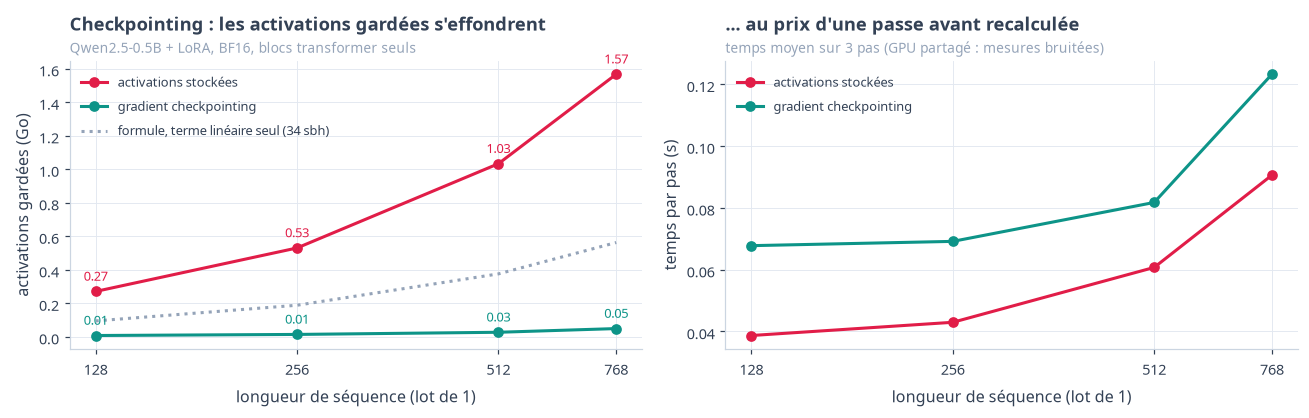

,séquence,checkpointing,activations (Go),pic (Go),temps par pas (s)
0,128,False,0.270,1.338,0.039
1,128,True,0.006,1.101,0.068
2,256,False,0.529,1.601,0.043
3,256,True,0.013,1.117,0.069
4,512,False,1.032,2.109,0.061
5,512,True,0.026,1.148,0.082
6,768,False,1.566,2.648,0.091
7,768,True,0.048,1.196,0.123


In [10]:
print(f"Logits FP32 de 384 tokens : {logits_bytes / GB:.2f} Go")


class _Out:
    def __init__(self, loss):
        self.loss = loss


class BackboneLoss(torch.nn.Module):
    """Enveloppe : passe dans les blocs du modèle et renvoie une perte factice sur les états cachés."""

    def __init__(self, causal_lm):
        super().__init__()
        self.backbone = causal_lm.model

    def forward(self, input_ids):
        h = self.backbone(input_ids=input_ids).last_hidden_state
        return _Out(h.float().pow(2).mean())


def run_blocks(seq, ck):
    tok, model = c7.load_fresh(llm.SMALL)
    model.config.use_cache = False
    if ck:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, target_modules="all-linear", task_type="CAUSAL_LM"))
    model.train()  # le checkpointing de transformers n'agit qu'en mode entraînement
    wrapped = BackboneLoss(model.get_base_model())
    ids = tok(texte * 3, return_tensors="pt")["input_ids"][:, :seq].cuda()
    torch.cuda.synchronize(); t = time.time()
    r = c7.measure_train_step(wrapped, {"input_ids": ids}, lambda ps: torch.optim.AdamW(ps, lr=1e-4), n_steps=3)
    r["temps par pas"] = (time.time() - t) / 3
    del model, wrapped; gc.collect(); torch.cuda.empty_cache()
    return r


ck_rows = []
for s_len in [128, 256, 512, 768]:
    for ck in [False, True]:
        r = c7.gpu_retry(run_blocks, s_len, ck)
        ck_rows.append({"séquence": s_len, "checkpointing": ck, "activations (Go)": r["activations"] / GB,
                        "pic (Go)": r["pic"] / GB, "temps par pas (s)": r["temps par pas"]})
ck_df = pd.DataFrame(ck_rows)
c7.log_vram("nb2 checkpointing")
spec_q = c7.MODEL_SPECS["Qwen2.5-0.5B"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ck, col, lab in [(False, ROSE, "activations stockées"), (True, TEAL, "gradient checkpointing")]:
    sub = ck_df[ck_df.checkpointing == ck]
    axes[0].plot(sub["séquence"], sub["activations (Go)"], "o-", color=col, label=lab)
    for s_, v_ in zip(sub["séquence"], sub["activations (Go)"]):
        axes[0].annotate(f"{v_:.2f}", (s_, v_), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5, color=col)
    axes[1].plot(sub["séquence"], sub["temps par pas (s)"], "o-", color=col, label=lab)
seqs_q = np.array([128, 256, 512, 768])
axes[0].plot(seqs_q, [c7.activation_memory(spec_q, s_, 1) / GB * 34 / (34 + 5 * spec_q.heads * s_ / spec_q.hidden) for s_ in seqs_q],
             ":", color=GRAY, label="formule, terme linéaire seul (34 sbh)")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xticks(seqs_q, [str(s_) for s_ in seqs_q]); ax.set_xlabel("longueur de séquence (lot de 1)")
axes[0].set_ylabel("activations gardées (Go)"); axes[0].legend(fontsize=8.5)
axes[1].set_ylabel("temps par pas (s)"); axes[1].legend(fontsize=8.5)
c7.title_sub(axes[0], "Checkpointing : les activations gardées s'effondrent", "Qwen2.5-0.5B + LoRA, BF16, blocs transformer seuls")
c7.title_sub(axes[1], "... au prix d'une passe avant recalculée", "temps moyen sur 3 pas (GPU partagé : mesures bruitées)")
plt.tight_layout(); plt.show()
ck_df.round(3)

Sans checkpointing, les activations gardées croissent linéairement avec la séquence
(l'attention de PyTorch, dite *SDPA*, ne stocke pas la matrice $s \times s$, d'où
l'absence de terme quadratique), à environ trois fois le terme $34\,sbh$ de la formule :
celle-ci a été établie pour GPT, alors que Qwen a une couche feed-forward plus large
(SwiGLU, $5{,}4\,h$) et des conversions en FP32 dans ses normalisations et adaptateurs.
Avec checkpointing, il ne reste que les entrées des 24 blocs ($2sbh$ octets chacun) :
un facteur de l'ordre de 20 à 30 en moins. En contrepartie, chaque pas refait une passe
avant pendant la passe arrière, d'où un temps par pas plus long. Sur un vrai finetuning de
petit modèle, n'oubliez pas que les **logits** (non concernés) peuvent rester le premier
poste.

> **À retenir.** Les formules prévoient très bien poids, gradients et états de
> l'optimiseur. Les activations sont plus difficiles à estimer (implémentation de
> l'attention, logits sur un grand vocabulaire) : **mesurez**. Le gradient checkpointing
> réduit la mémoire des activations au prix de calculs supplémentaires.

## 4. Représentations numériques (section *Numerical Representations*)

**Le problème.** Chaque valeur du modèle occupe $M$ octets ; diviser $M$ par deux divise
par deux la mémoire des poids. Mais avec moins de bits, on représente moins de nombres.

Un flottant IEEE 754 comporte 1 bit de **signe**, $e$ bits d'**exposant** (qui fixent la
**plage**) et $m$ bits de **mantisse** (qui fixent la **précision**). Un nombre normal vaut
$$x = (-1)^{\text{signe}} \times 1{,}\text{mantisse}_2 \times 2^{\,\text{exposant} - \text{biais}},
  \qquad \text{biais} = 2^{e-1} - 1.$$
FP16 et BF16 ont tous deux 16 bits, mais BF16 (conçu par Google pour les TPU) garde les
8 bits d'exposant de FP32 : même plage, moins de précision. TF32 (NVIDIA) n'a en fait que
19 bits utiles malgré son nom, ce qui amuse beaucoup l'auteure dans une note de bas de page.

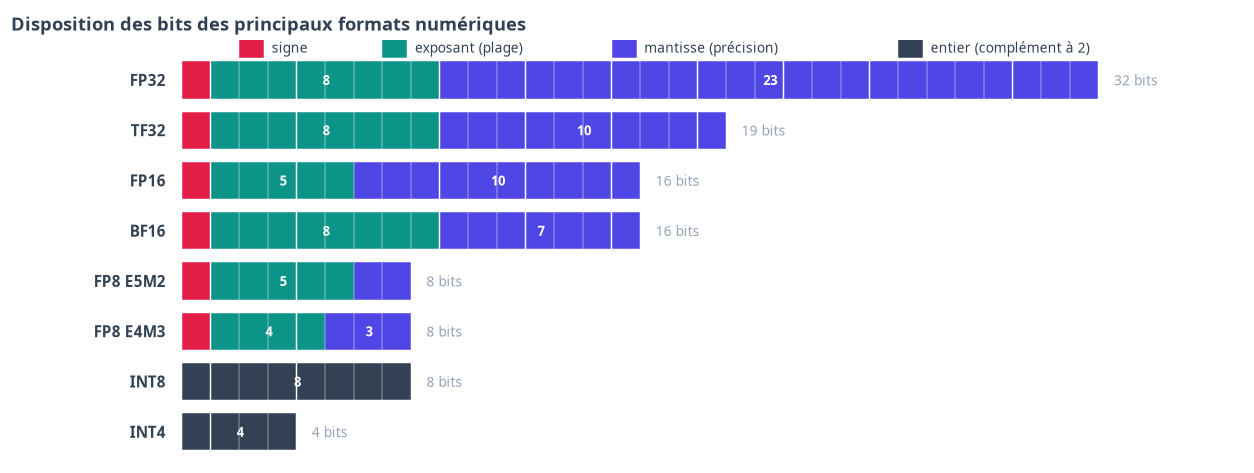

,bits,max,plus petit normal,plus petit sous-normal,epsilon (écart relatif),chiffres décimaux
FP32,32,3.4e+38,1.18e-38,1.4e-45,1.19e-07,7.2
TF32,19,3.4e+38,1.18e-38,1.15e-41,0.000977,3.3
FP16,16,6.55e+04,6.1e-05,5.96e-08,0.000977,3.3
BF16,16,3.39e+38,1.18e-38,9.18e-41,0.00781,2.4
FP8 E5M2,8,5.73e+04,6.1e-05,1.53e-05,0.25,0.9
FP8 E4M3,8,448,0.0156,0.00195,0.125,1.2


In [11]:
fmts = [("FP32", 1, 8, 23), ("TF32", 1, 8, 10), ("FP16", 1, 5, 10), ("BF16", 1, 8, 7),
        ("FP8 E5M2", 1, 5, 2), ("FP8 E4M3", 1, 4, 3), ("INT8", 0, 0, 8), ("INT4", 0, 0, 4)]
fig, ax = plt.subplots(figsize=(11.5, 4.4))
for i, (name, s_, e_, m_) in enumerate(fmts):
    x0 = 0
    for nbits, col, lab in [(s_, ROSE, "signe"), (e_, TEAL, "exposant : plage"), (m_, INDIGO if e_ else SLATE, "mantisse : précision")]:
        for k in range(nbits):
            ax.add_patch(plt.Rectangle((x0 + k, -i - 0.35), 0.92, 0.7, color=col))
        if nbits >= 3:
            ax.text(x0 + nbits / 2, -i, f"{nbits}", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
        x0 += nbits
    ax.text(-0.6, -i, name, ha="right", va="center", fontsize=10, fontweight="bold", color=SLATE)
    ax.text(x0 + 0.5, -i, f"{s_ + e_ + m_} bits", va="center", fontsize=9, color=GRAY)
ax.set_xlim(-6, 37); ax.set_ylim(-len(fmts) + 0.4, 0.8); ax.axis("off")
for col, lab, xx in [(ROSE, "signe", 2), (TEAL, "exposant (plage)", 7), (INDIGO, "mantisse (précision)", 15),
                     (SLATE, "entier (complément à 2)", 25)]:
    ax.add_patch(plt.Rectangle((xx, 0.45), 0.8, 0.4, color=col)); ax.text(xx + 1.1, 0.65, lab, va="center", fontsize=9)
ax.set_title("Disposition des bits des principaux formats numériques", loc="left")
plt.tight_layout(); plt.show()

infos = [c7.float_info(n) for n in c7.FLOAT_FORMATS]
pd.DataFrame({"bits": [i.bits for i in infos], "max": [f"{i.max:.3g}" for i in infos],
              "plus petit normal": [f"{i.min_normal:.3g}" for i in infos],
              "plus petit sous-normal": [f"{i.min_subnormal:.3g}" for i in infos],
              "epsilon (écart relatif)": [f"{i.eps:.3g}" for i in infos],
              "chiffres décimaux": [f"{i.decimal_digits:.1f}" for i in infos]},
             index=[i.name for i in infos])

Voici les bits réels de quelques nombres, lus directement dans la mémoire de tenseurs
PyTorch (`c7.float_bits`). Pour passer de FP32 à BF16, il suffit (à l'arrondi près) de
tronquer les 16 derniers bits : c'est ce qui rend les conversions FP32 <-> BF16 si
simples.

In [12]:
rows = []
for val in [1.0, 0.1, -2.5, 65504.0, 1e-5]:
    for f in ["FP32", "FP16", "BF16"]:
        s_, e_, m_ = c7.float_bits(val, f)
        back = torch.tensor([val], dtype={"FP32": torch.float32, "FP16": torch.float16, "BF16": torch.bfloat16}[f]).item()
        rows.append({"valeur": val, "format": f, "signe": s_, "exposant": e_, "mantisse": m_, "valeur stockée": f"{back:.9g}"})
pd.DataFrame(rows).set_index(["valeur", "format"])

signe  exposant                 mantisse  valeur stockée
valeur       format                                                         
 1.00000     FP32       0  01111111  00000000000000000000000               1
             FP16       0     01111               0000000000               1
             BF16       0  01111111                  0000000               1
 0.10000     FP32       0  01111011  10011001100110011001101     0.100000001
             FP16       0     01011               1001100110    0.0999755859
             BF16       0  01111011                  1001101     0.100097656
-2.50000     FP32       1  10000000  01000000000000000000000            -2.5
             FP16       1     10000               0100000000            -2.5
             BF16       1  10000000                  0100000            -2.5
 65504.00000 FP32       0  10001110  11111111110000000000000           65504
             FP16       0     11110               1111111111           65504
             BF16       0  10001111                  0000000           65536
 0.00001     FP32       0  01101110  01001111100010110101100  9.99999975e-06
             FP16       0     00000               0010101000  1.00135803e-05
             BF16       0  01101110                  0101000  1.00135803e-05

**Le tableau 7-3 du livre, recalculé.** On convertit des valeurs FP32 vers FP16, BF16 et
TF32 avec `c7.round_to_float`, qui simule l'arrondi au plus proche dans n'importe quel
format (et coïncide bit à bit avec PyTorch, voir les tests). Les valeurs hors plage
deviennent infinies en FP16.

,FP32,FP16,BF16,TF32
0,0.0123456789,0.01234436035,0.01232910156,0.01234436035
1,0.123456789,0.1234741211,0.1235351562,0.1234741211
2,1.23456789,1.234375,1.234375,1.234375
3,12.3456789,12.34375,12.375,12.34375
4,123.456789,123.4375,123.5,123.4375
5,1234.56789,1235,1232,1235
6,12345.6789,12344,12352,12344
7,123456.789,inf,123392,123456
8,1234567.89,inf,1236992,1234944


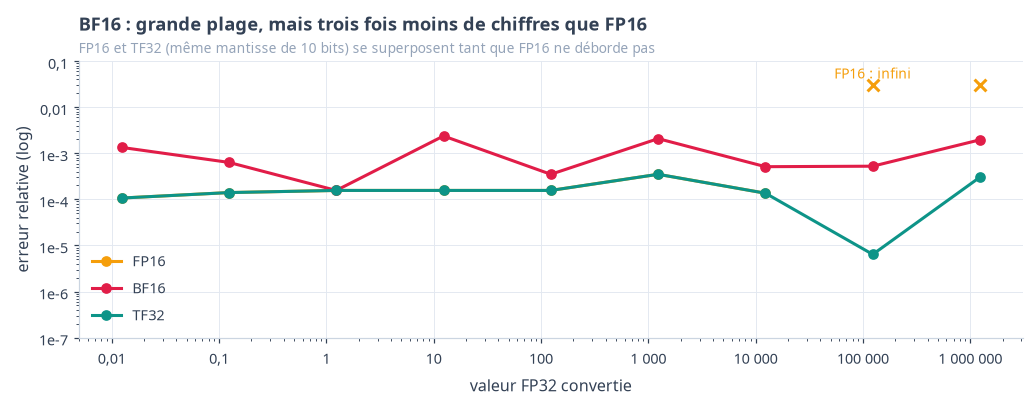

In [13]:
vals = np.array([0.0123456789, 0.123456789, 1.23456789, 12.3456789, 123.456789, 1234.56789, 12345.6789,
                 123456.789, 1234567.89])
t73 = pd.DataFrame({"FP32": vals, **{f: c7.round_to_float(vals, f) for f in ["FP16", "BF16", "TF32"]}})
err = pd.DataFrame({f"erreur relative {f}": c7.relative_error(vals, t73[f]) for f in ["FP16", "BF16", "TF32"]})
display(t73.map(lambda v: f"{v:.10g}"))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
for f, col in [("FP16", AMBER), ("BF16", ROSE), ("TF32", TEAL)]:
    e = c7.relative_error(vals, t73[f])
    ax.plot(vals[np.isfinite(e)], e[np.isfinite(e)], "o-", color=col, label=f)
    if not np.all(np.isfinite(e)):
        ax.scatter(vals[~np.isfinite(e)], [3e-2] * (~np.isfinite(e)).sum(), marker="x", s=60, color=col)
        ax.text(vals[~np.isfinite(e)][0], 4.2e-2, "FP16 : infini", color=col, fontsize=9, ha="center")
ax.set_xscale("log"); ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "x")
ax.set_xlabel("valeur FP32 convertie"); ax.set_ylabel("erreur relative (log)")
ax.legend(); ax.set_ylim(1e-7, 1e-1)
c7.title_sub(ax, "BF16 : grande plage, mais trois fois moins de chiffres que FP16",
             "FP16 et TF32 (même mantisse de 10 bits) se superposent tant que FP16 ne déborde pas")
plt.tight_layout(); plt.show()

**L'espacement entre nombres représentables.** Un flottant garde une précision
**relative** constante ($\approx 2^{-m}$) : l'écart absolu entre deux voisins double à chaque
puissance de 2, jusqu'au maximum du format. La figure montre cet écart pour chaque format.

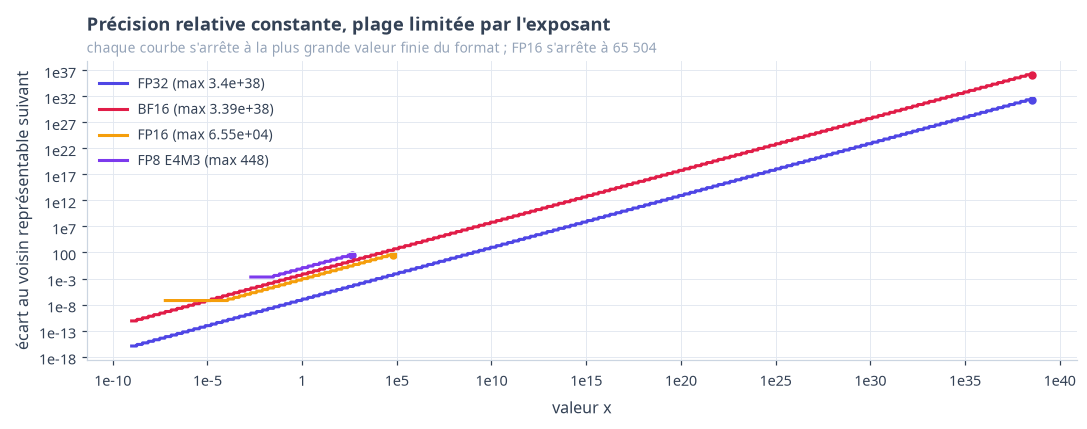

In [14]:
xs = np.logspace(-9, 39, 2000)
fig, ax = plt.subplots(figsize=(10, 4))
for f, col in [("FP32", INDIGO), ("BF16", ROSE), ("FP16", AMBER), ("FP8 E4M3", VIOLET)]:
    inf_ = c7.float_info(f); e_, m_ = c7.FLOAT_FORMATS[f]; bias = 2 ** (e_ - 1) - 1
    xx = xs[(xs >= inf_.min_subnormal) & (xs <= inf_.max)]
    spacing = 2.0 ** (np.maximum(np.floor(np.log2(xx)), 1 - bias) - m_)
    ax.loglog(xx, spacing, color=col, label=f"{f} (max {inf_.max:.3g})")
    ax.scatter([xx[-1]], [spacing[-1]], color=col, s=20)
c7.sci_log(ax, "both"); ax.set_xlabel("valeur x"); ax.set_ylabel("écart au voisin représentable suivant")
ax.legend(fontsize=9)
c7.title_sub(ax, "Précision relative constante, plage limitée par l'exposant",
             "chaque courbe s'arrête à la plus grande valeur finie du format ; FP16 s'arrête à 65 504")
plt.tight_layout(); plt.show()

**Charger un modèle dans le bon format.** Le livre raconte les déboires des équipes qui ont
chargé Llama 2 (publié en BF16) en FP16 : des activations au-delà de 65 504 deviennent
infinies et la qualité s'effondre. Testons Qwen2.5-0.5B (publié en BF16) dans les trois
formats, en mesurant la perplexité sur un petit corpus français et la plus grande
activation observée.

In [15]:
llm.free_gpu()


def ppl_in(dtype):
    tok, model = c7.load_fresh(llm.SMALL, dtype)
    acts = []
    hooks = [l.register_forward_hook(lambda m_, i_, o_: acts.append((o_[0] if isinstance(o_, tuple) else o_).float().abs().max().item()))
             for l in model.model.layers]
    p = c7.perplexity_texts(model, tok)
    for h_ in hooks:
        h_.remove()
    del model; gc.collect(); torch.cuda.empty_cache()
    return p, max(acts)


fmt_res = {dt: c7.gpu_retry(ppl_in, dt) for dt in ["float32", "bfloat16", "float16"]}
c7.log_vram("nb2 formats")
fr = pd.DataFrame(fmt_res, index=["perplexité", "max |activation|"]).T
fr["marge avant 65 504 (FP16)"] = 65504 / fr["max |activation|"]
fr.round(2)

,perplexité,max |activation|,marge avant 65 504 (FP16)
float32,15.83,1617.94,40.49
bfloat16,16.02,1608.00,40.74
float16,15.80,1619.00,40.46


Pour ce modèle, les trois formats donnent des perplexités très proches et la plus grande
activation reste loin sous la limite de FP16 : Qwen2.5-0.5B tolère le FP16. Ce n'est pas
une garantie générale : la marge n'est que d'un facteur indiqué dans la dernière colonne,
et des modèles plus grands présentent des activations aberrantes bien plus fortes. La
règle du livre reste valable : **chargez un modèle dans le format prévu par ses auteurs**.

**Pourquoi l'entraînement est plus sensible.** Deux expériences de pensée, exécutées :

1. **Accumulation** : additionner 20 000 fois $10^{-4}$ devrait donner 2. En FP16 ou en
   BF16, la somme cesse de croître dès que l'incrément devient plus petit que la moitié de
   l'écart entre deux nombres représentables (phénomène de *swamping*).
2. **Mise à jour de poids** : ajouter un petit pas $\eta g = 10^{-4}$ à un poids égal à 1
   en BF16 ne change rien (l'écart entre 1 et son voisin est $2^{-7} \approx 0{,}0078$). D'où
   la copie **maîtresse** des poids en FP32 dans l'entraînement en précision mixte.

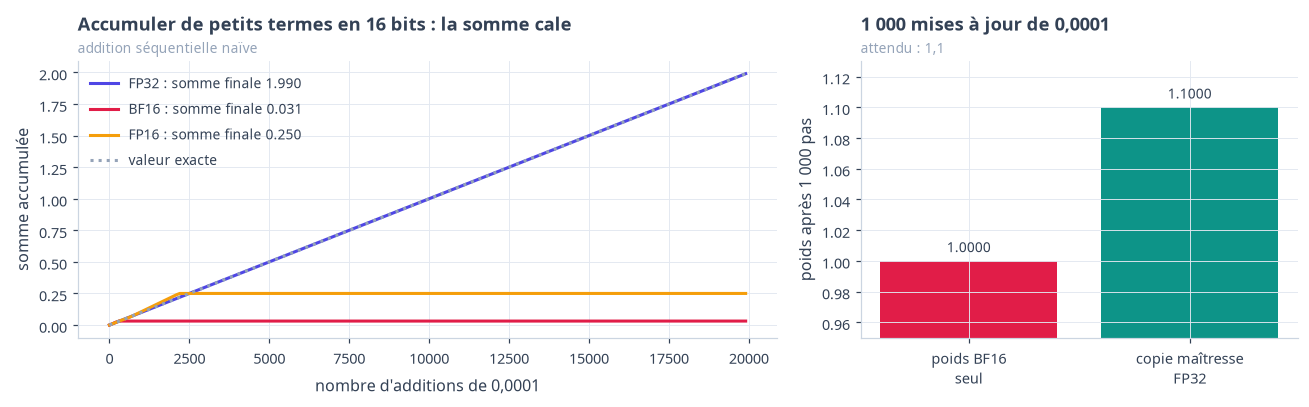

In [16]:
n_add = 20000
curves = {}
for name, dt in [("FP32", torch.float32), ("BF16", torch.bfloat16), ("FP16", torch.float16)]:
    acc = torch.zeros((), dtype=dt); inc = torch.tensor(1e-4, dtype=dt); hist = []
    for k in range(n_add):
        acc = acc + inc
        if k % 100 == 0:
            hist.append(acc.item())
    curves[name] = hist
w_bf = torch.tensor(1.0, dtype=torch.bfloat16); w_master = torch.tensor(1.0, dtype=torch.float32)
for _ in range(1000):
    w_bf = w_bf + torch.tensor(1e-4, dtype=torch.bfloat16)
    w_master = w_master + 1e-4

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
steps = np.arange(0, n_add, 100)
for (name, h_), col in zip(curves.items(), [INDIGO, ROSE, AMBER]):
    axes[0].plot(steps, h_, color=col, label=f"{name} : somme finale {h_[-1]:.3f}")
axes[0].plot(steps, steps * 1e-4, color=GRAY, ls=":", label="valeur exacte")
axes[0].set_xlabel("nombre d'additions de 0,0001"); axes[0].set_ylabel("somme accumulée"); axes[0].legend(fontsize=9)
c7.title_sub(axes[0], "Accumuler de petits termes en 16 bits : la somme cale", "addition séquentielle naïve")
axes[1].bar(["poids BF16\nseul", "copie maîtresse\nFP32"], [w_bf.item(), w_master.item()], color=[ROSE, TEAL])
annotate_bars(axes[1], "{:.4f}"); axes[1].set_ylim(0.95, 1.13); axes[1].set_ylabel("poids après 1 000 pas")
c7.title_sub(axes[1], "1 000 mises à jour de 0,0001", "attendu : 1,1")
plt.tight_layout(); plt.show()

> **À retenir.** Un format flottant partage ses bits entre **plage** (exposant) et
> **précision** (mantisse). FP16 est précis mais étroit (max 65 504) ; BF16 a la plage de
> FP32 mais 2 à 3 chiffres significatifs. Les petites mises à jour et les accumulations
> souffrent de la basse précision : on entraîne en **précision mixte** (copie FP32 des
> poids, calculs en 16 bits).

## 5. Quantification : principes (section *Quantization*)

**Quantifier**, au sens strict, c'est passer à un format **entier** ; le livre (et la
littérature) emploie le mot pour toute réduction de précision. Deux décisions :
**quoi** quantifier (les poids, le plus souvent, car c'est plus stable que les
activations) et **quand** (après l'entraînement, *post-training quantization* ou PTQ, de
loin le plus courant ; ou pendant, voir section 8).

Les deux schémas de base, implémentés dans le module :

- **absmax (symétrique)** : $s = \max|x| / (2^{b-1}-1)$, $q = \text{round}(x/s)$,
  $\hat x = s\,q$. Le zéro est exact ; si les valeurs ne sont pas centrées, la moitié de la
  grille peut rester inutilisée.
- **zéro-point (asymétrique)** : $s = (\max - \min)/(2^b - 1)$, $z = \text{round}(-\min/s)$,
  $q = \text{round}(x/s) + z$, $\hat x = s\,(q - z)$. Toute la grille couvre $[\min, \max]$.

Dans les deux cas, l'erreur d'arrondi est au plus $s/2$ par valeur : **tout ce qui
augmente l'échelle $s$ (une valeur aberrante, une plage asymétrique) dégrade toutes les
autres valeurs**.

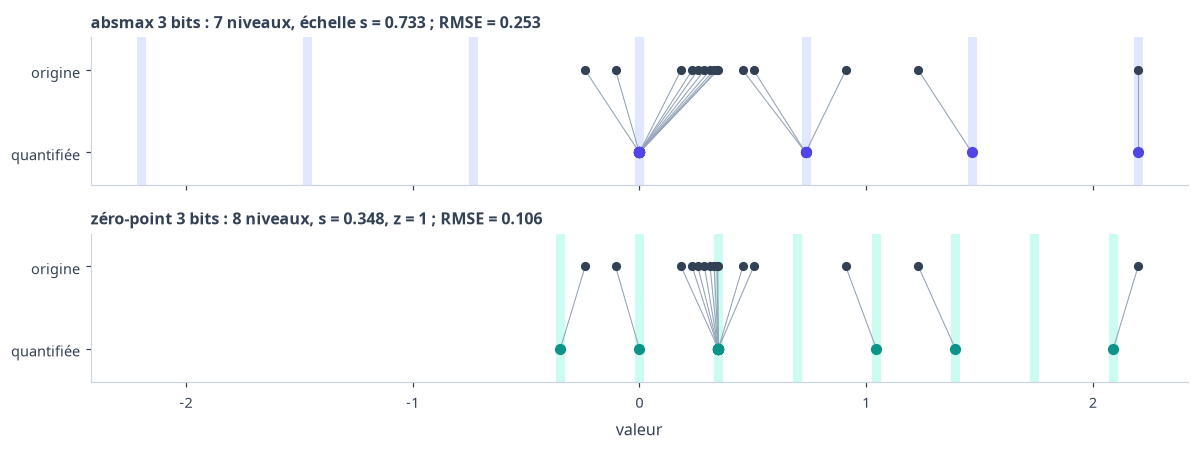

In [17]:
rng = np.random.default_rng(3)
xv = np.concatenate([rng.normal(0.4, 0.25, 14), [2.2]])  # valeurs décalées + une valeur aberrante
qa, sa = c7.quantize_absmax(xv, 3)
qz, sz, zz = c7.quantize_zeropoint(xv, 3)
fig, axes = plt.subplots(2, 1, figsize=(11, 4.2), sharex=True)
for ax, rec, grid, title, col in [
        (axes[0], c7.dequantize_absmax(qa, sa), sa * np.arange(-3, 4), f"absmax 3 bits : 7 niveaux, échelle s = {sa:.3f}", INDIGO),
        (axes[1], c7.dequantize_zeropoint(qz, sz, zz), sz * (np.arange(8) - zz), f"zéro-point 3 bits : 8 niveaux, s = {sz:.3f}, z = {zz}", TEAL)]:
    for gv in grid:
        ax.axvline(gv, color=LIGHT[col], lw=6, zorder=0)
    ax.scatter(xv, np.ones_like(xv), color=SLATE, s=25, zorder=3, label="valeur d'origine")
    ax.scatter(rec, np.zeros_like(rec), color=col, s=40, zorder=3, label="valeur quantifiée")
    for a_, b_ in zip(xv, rec):
        ax.plot([a_, b_], [1, 0], color=GRAY, lw=0.7, zorder=2)
    ax.set_yticks([0, 1], ["quantifiée", "origine"]); ax.set_ylim(-0.4, 1.4); ax.grid(False)
    e = c7.quant_error(xv, rec)
    ax.set_title(f"{title} ; RMSE = {e['rmse']:.3f}", fontsize=10.5)
axes[1].set_xlabel("valeur")
plt.tight_layout(); plt.show()

La valeur aberrante (2,2) fixe l'échelle : la plupart des valeurs, entre 0 et 0,8, se
partagent deux ou trois niveaux seulement. Le zéro-point récupère les niveaux négatifs
inutilisés par l'absmax. Le remède le plus efficace contre les valeurs aberrantes est la
**quantification par groupe** : une échelle par bloc de $g$ valeurs (64 ou 128 typiquement),
de sorte qu'une valeur extrême ne pénalise que son groupe. Le coût est le stockage des
échelles : $b + 16/g$ bits par poids avec des échelles en 16 bits (4,25 bits pour INT4 avec
$g = 64$).

> **À retenir.** Quantifier = choisir une échelle (et un zéro), arrondir, borner. L'erreur
> est proportionnelle à l'échelle, donc à la plage du bloc : quantifier **par groupe**
> limite l'effet des valeurs aberrantes pour un surcoût de quelques centièmes de bit.

## 6. Quantifier de vrais poids (section *Inference quantization*)

Passons aux poids de Qwen2.5-0.5B. Leur distribution conditionne le choix du schéma :
l'intuition de **NF4** (NormalFloat-4, utilisé par QLoRA) est que les poids pré-entraînés
suivent à peu près une loi normale centrée ; plutôt qu'une grille uniforme, on place les
16 niveaux aux **quantiles** de la loi normale, pour que chaque niveau soit utilisé aussi
souvent que les autres.

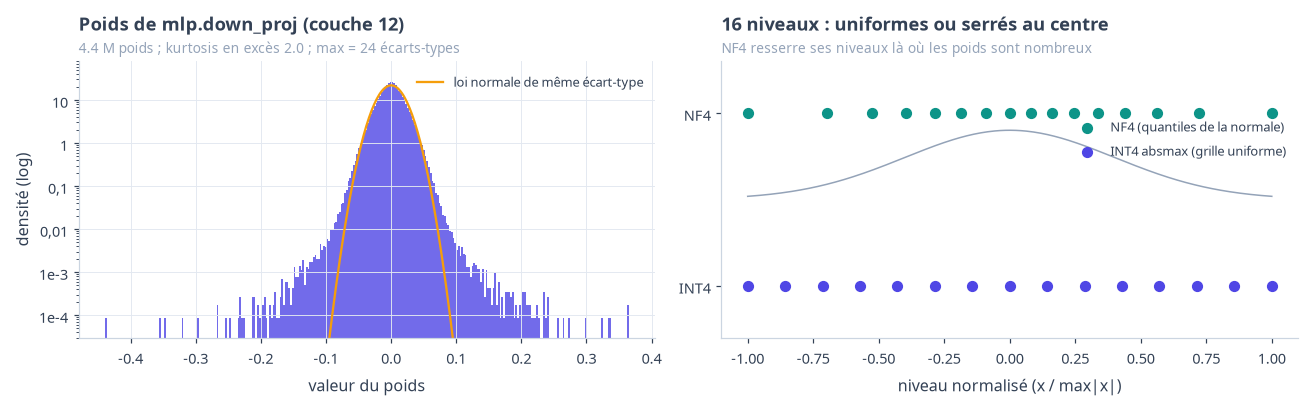

In [18]:
llm.free_gpu()
tokq, mq = c7.load_fresh(llm.SMALL)
W_down = mq.model.layers[12].mlp.down_proj.weight.detach().float()
W_q = mq.model.layers[12].self_attn.q_proj.weight.detach().float()
wd = W_down.cpu().numpy().ravel()
from scipy.stats import kurtosis, norm

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sd = wd.std()
axes[0].hist(wd, bins=300, density=True, color=INDIGO, alpha=0.8, log=True)
xx = np.linspace(wd.min(), wd.max(), 400)
axes[0].plot(xx, norm.pdf(xx, wd.mean(), sd), color=AMBER, lw=1.5, label="loi normale de même écart-type")
axes[0].set_ylim(3e-5, 80); c7.sci_log(axes[0], "y")
axes[0].set_xlabel("valeur du poids"); axes[0].set_ylabel("densité (log)"); axes[0].legend(fontsize=8.5)
c7.title_sub(axes[0], "Poids de mlp.down_proj (couche 12)",
             f"{wd.size / 1e6:.1f} M poids ; kurtosis en excès {kurtosis(wd):.1f} ; max = {np.abs(wd).max() / sd:.0f} écarts-types")
u = np.linspace(-1, 1, 15)
axes[1].scatter(c7.NF4_LEVELS, np.ones(16), color=TEAL, s=40, label="NF4 (quantiles de la normale)")
axes[1].scatter(np.arange(-7, 8) / 7, np.zeros(15), color=INDIGO, s=40, label="INT4 absmax (grille uniforme)")
xn = np.linspace(-1, 1, 300)
axes[1].plot(xn, 0.5 + 0.4 * norm.pdf(xn, 0, 1 / 2.5) / norm.pdf(0, 0, 1 / 2.5), color=GRAY, lw=1)
axes[1].set_yticks([0, 1], ["INT4", "NF4"]); axes[1].set_ylim(-0.3, 1.3); axes[1].set_xlabel("niveau normalisé (x / max|x|)")
axes[1].legend(fontsize=8.5, loc="center right", bbox_to_anchor=(1.0, 0.72)); axes[1].grid(False)
c7.title_sub(axes[1], "16 niveaux : uniformes ou serrés au centre", "NF4 resserre ses niveaux là où les poids sont nombreux")
plt.tight_layout(); plt.show()

Les poids sont bien centrés et en cloche, mais avec des **queues lourdes** : quelques
valeurs atteignent des dizaines d'écarts-types. C'est exactement le cas où une échelle
unique pour tout le tenseur est désastreuse. Mesurons le rapport signal sur bruit de
quantification (SQNR, en dB : $20 \log_{10}(\|x\| / \|x - \hat x\|)$, plus c'est haut,
mieux c'est) selon la granularité de l'échelle et le schéma.

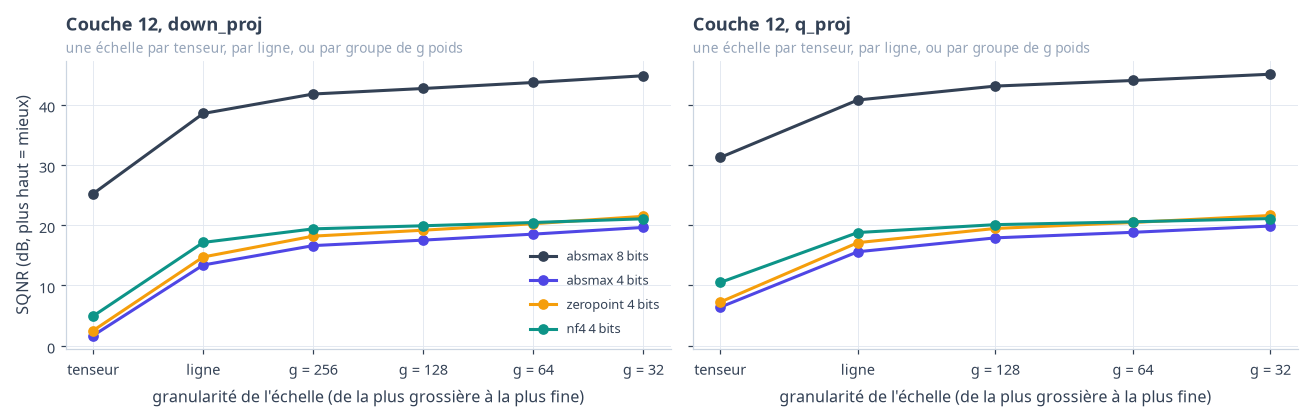

In [19]:
grans = [("tenseur", -1), ("ligne", None), ("g = 256", 256), ("g = 128", 128), ("g = 64", 64), ("g = 32", 32)]
rows = []
for W, wname in [(W_down, "down_proj"), (W_q, "q_proj")]:
    for gname, gs in grans:
        if gs and gs > 0 and W.shape[1] % gs:
            continue
        for meth, bits in [("absmax", 8), ("absmax", 4), ("zeropoint", 4), ("nf4", 4)]:
            rec = c7.fake_quantize_weight(W, bits, gs, meth)
            e = c7.quant_error(W.cpu().numpy(), rec.cpu().numpy())
            rows.append({"matrice": wname, "granularité": gname, "schéma": f"{meth} {bits} bits", "SQNR (dB)": e["sqnr (dB)"]})
qe = pd.DataFrame(rows)
c7.log_vram("nb2 sqnr")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, wname in zip(axes, ["down_proj", "q_proj"]):
    sub = qe[qe.matrice == wname]
    for (sch, col) in zip(["absmax 8 bits", "absmax 4 bits", "zeropoint 4 bits", "nf4 4 bits"], [SLATE, INDIGO, AMBER, TEAL]):
        s_ = sub[sub["schéma"] == sch]
        ax.plot(s_["granularité"], s_["SQNR (dB)"], "o-", color=col, label=sch)
    ax.set_xlabel("granularité de l'échelle (de la plus grossière à la plus fine)")
    c7.title_sub(ax, f"Couche 12, {wname}", "une échelle par tenseur, par ligne, ou par groupe de g poids")
axes[0].set_ylabel("SQNR (dB, plus haut = mieux)"); axes[0].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Trois enseignements, mesurés sur de vrais poids :

- chaque bit gagné vaut environ 6 dB ($20\log_{10} 2$) : INT8 est loin devant INT4 ;
- en 4 bits, une échelle par **tenseur** est catastrophique (les valeurs aberrantes
  écrasent la grille) ; par ligne, puis par groupe de 64 à 128, on regagne beaucoup ;
- à granularité égale, **NF4** bat la grille uniforme, car il colle à la forme en cloche
  des poids.

> **À retenir.** Sur des poids réels (en cloche, à queues lourdes), la granularité de
> l'échelle compte autant que le nombre de bits. INT4 par groupe de 64 à 128, ou NF4, est le
> point de fonctionnement usuel.

## 7. Impact sur la perplexité et vraie quantification (section *Inference quantization*)

Le SQNR mesure l'erreur sur les poids ; ce qui compte est l'effet sur le **modèle**. On
quantifie (en simulation : les valeurs sont quantifiées puis déquantifiées) **toutes** les
couches linéaires de Qwen2.5-0.5B avec `c7.quantize_model_`, on mesure la perplexité sur
le corpus français, puis on restaure les poids d'origine.

In [20]:
configs_q = [("BF16 (référence)", None), ("INT8 par ligne", (8, None, "absmax")),
             ("INT4 g=128 absmax", (4, 128, "absmax")), ("INT4 g=128 zéro-point", (4, 128, "zeropoint")),
             ("NF4 g=64", (4, 64, "nf4")), ("INT4 par ligne", (4, None, "absmax")),
             ("INT3 g=64 zéro-point", (3, 64, "zeropoint")), ("INT4 par tenseur", (4, -1, "absmax"))]
n_lin = sum(m_.weight.numel() for _, m_ in c7.linear_layers(mq))
n_tot = sum(p.numel() for p in mq.parameters())
rows = []
for name, cfg in configs_q:
    if cfg is None:
        bits_eff = 16
        ppl = c7.perplexity_texts(mq, tokq)
    else:
        b_, gs, meth = cfg
        backup = c7.quantize_model_(mq, b_, gs, meth)
        ppl = c7.perplexity_texts(mq, tokq)
        c7.restore_weights_(mq, backup)
        bits_eff = c7.effective_bits(b_, gs if gs and gs > 0 else None, zero_bits=8 if meth == "zeropoint" else 0)
    mem_ = (n_lin * bits_eff / 8 + (n_tot - n_lin) * 2) / GB
    rows.append({"configuration": name, "bits par poids (linéaires)": bits_eff, "perplexité": ppl, "mémoire (Go)": mem_})
pq = pd.DataFrame(rows).set_index("configuration")
c7.log_vram("nb2 ppl quant")
pq.round(3)

,bits par poids (linéaires),perplexité,mémoire (Go)
configuration,,,
BF16 (référence),16.000,1.602000e+01,0.988
INT8 par ligne,8.000,1.587800e+01,0.630
INT4 g=128 absmax,4.125,2.325100e+01,0.457
INT4 g=128 zéro-point,4.188,2.009200e+01,0.460
NF4 g=64,4.250,1.854900e+01,0.463
INT4 par ligne,4.000,3.840500e+01,0.451
INT3 g=64 zéro-point,3.375,5.355000e+01,0.423
INT4 par tenseur,4.000,3.504851e+07,0.451


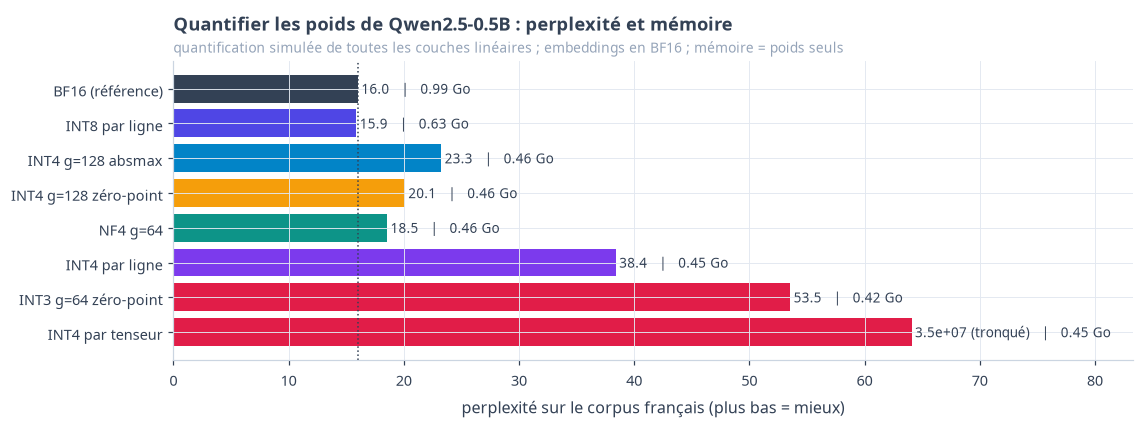

In [21]:
fig, ax = plt.subplots(figsize=(10.5, 4))
ref = pq.loc["BF16 (référence)", "perplexité"]
colors_q = [SLATE, INDIGO, SKY, AMBER, TEAL, VIOLET, ROSE, ROSE]
ppl_plot = np.minimum(pq["perplexité"], ref * 4)
ax.barh(pq.index, ppl_plot, color=colors_q)
for i, (p_, m_) in enumerate(zip(pq["perplexité"], pq["mémoire (Go)"])):
    lab = f"{p_:.1f}" if p_ < ref * 4 else f"{p_:.3g} (tronqué)"
    ax.text(ppl_plot.iloc[i] + 0.3, i, f"{lab}   |   {m_:.2f} Go", va="center", fontsize=8.8)
ax.axvline(ref, color=SLATE, ls=":", lw=1)
ax.invert_yaxis(); ax.set_xlabel("perplexité sur le corpus français (plus bas = mieux)"); ax.set_xlim(0, ref * 5.2)
c7.title_sub(ax, "Quantifier les poids de Qwen2.5-0.5B : perplexité et mémoire",
             "quantification simulée de toutes les couches linéaires ; embeddings en BF16 ; mémoire = poids seuls")
plt.tight_layout(); plt.show()

INT8 est pratiquement gratuit ; INT4 par groupe (absmax, zéro-point ou NF4) coûte un peu
de perplexité pour diviser par environ 3 la mémoire des couches linéaires ; à 3 bits la
dégradation devient sensible, et INT4 avec une échelle par tenseur détruit le modèle.
Un modèle de 0,5 milliard de paramètres est d'ailleurs plus fragile qu'un grand : les
grands modèles encaissent mieux la quantification.

**Vraie quantification avec bitsandbytes.** Ce qui précède simulait l'arrondi. La
bibliothèque `bitsandbytes` stocke réellement les poids en 8 bits (LLM.int8(), Dettmers et
al., 2022) ou 4 bits (NF4, Dettmers et al., 2023) et les déquantifie à la volée pendant le
calcul. Elle fonctionne sur ce GPU Blackwell (RTX 5070).

In [22]:
del mq; llm.free_gpu()
from transformers import BitsAndBytesConfig


def load_bnb(kind):
    if kind == "BF16":
        tok, m_ = c7.load_fresh(llm.SMALL)
    else:
        cfg = (BitsAndBytesConfig(load_in_8bit=True) if kind == "INT8 (LLM.int8)" else
               BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16))
        # LLM.int8() calcule en FP16 : on charge le reste du modèle en FP16 pour éviter les conversions
        tok, m_ = c7.load_fresh(llm.SMALL, "float16" if kind.startswith("INT8") else "bfloat16",
                                quantization_config=cfg, device_map="cuda")
    p = c7.perplexity_texts(m_, tok)
    t = time.time()
    enc = tok("Le finetuning permet", return_tensors="pt").to("cuda")
    with torch.no_grad():
        m_.generate(**enc, max_new_tokens=32, do_sample=False, min_new_tokens=32, pad_token_id=tok.pad_token_id)
    r = {"empreinte mémoire (Go)": m_.get_memory_footprint() / GB, "perplexité": p,
         "débit (tokens/s, lot de 1)": 32 / (time.time() - t)}
    del m_; gc.collect(); torch.cuda.empty_cache()
    return r


bnb = pd.DataFrame({k: c7.gpu_retry(load_bnb, k) for k in ["BF16", "INT8 (LLM.int8)", "NF4 (4 bits)"]}).T
c7.log_vram("nb2 bnb")
bnb.round(3)

,empreinte mémoire (Go),perplexité,"débit (tokens/s, lot de 1)"
BF16,0.988,16.020,156.327
INT8 (LLM.int8),0.630,15.945,38.256
NF4 (4 bits),0.451,18.549,138.552


Les empreintes mesurées suivent les calculs : les couches linéaires sont divisées par 2 en
INT8 et par environ 4 en NF4, mais les embeddings (136 M paramètres sur 494 M ici, à cause
du grand vocabulaire) restent en 16 bits, ce qui limite le gain global. Le débit illustre
la remarque du livre : réduire la précision **ne réduit pas toujours la latence**.
LLM.int8() est ici bien plus lent que BF16 (sa décomposition des valeurs aberrantes et ses
conversions coûtent cher), alors que NF4 reste proche de BF16 (un peu au-dessus ou un peu
en dessous selon les exécutions) : le décodage d'un lot de 1 est limité par la bande
passante mémoire, et lire 4 bits par poids au lieu de 16 compense en grande partie la
déquantification. (Mesures bruitées : le GPU est partagé.)

Le livre évoque aussi les limites extrêmes : des modèles à 1 bit (BinaryConnect, XNOR-Net,
BitNet) et BitNet b1.58, dont chaque poids prend une valeur parmi $\{-1, 0, 1\}$
($\log_2 3 \approx 1{,}58$ bit) et qui égale un Llama 16 bits jusqu'à 3,9 B paramètres
(tableau 7-4). Ces modèles sont **entraînés** ainsi dès le départ : la quantification
a posteriori à si peu de bits échoue, comme l'a montré notre ligne INT3.

> **À retenir.** INT8 est presque sans perte, 4 bits par groupe (ou NF4) est le compromis
> standard pour l'inférence, en dessous la qualité chute vite. La mémoire diminue ; la
> latence, pas forcément.

## 8. Entraîner en basse précision (section *Training quantization*)

Le livre distingue deux objectifs : obtenir un modèle qui **reste bon une fois quantifié**,
et **réduire le coût de l'entraînement** lui-même.

- **QAT** (*quantization-aware training*) : on simule la quantification pendant
  l'entraînement, pour que le modèle apprenne à s'en accommoder. Les calculs restent en
  haute précision : la QAT ne rend pas l'entraînement moins cher (plutôt l'inverse). La
  difficulté technique est que l'arrondi a une dérivée nulle presque partout ; on utilise
  l'**estimateur « straight-through »** (STE) : en passe avant on quantifie, en passe
  arrière on fait comme si la quantification était l'identité.
- **Entraînement en basse précision** : il réduit vraiment le coût (Character.AI dit
  entraîner entièrement en INT8), mais la rétropropagation est sensible aux arrondis (voir
  la section 4). On le fait en **précision mixte** : copie maîtresse des poids en haute
  précision, activations et gradients en 16 ou 8 bits ; la fonction AMP (*automatic mixed
  precision*) des frameworks choisit automatiquement les opérations à faire en basse
  précision.

**Démonstration de la QAT** sur une régression linéaire dont les poids doivent finir en
**2 bits** (trois niveaux $\{-s, 0, s\}$, $s = \max|w|$). Comme un vrai réseau, le modèle
est **sur-paramétré** : 256 poids appliqués à des caractéristiques redondantes (projection
aléatoire de 64 variables), si bien que beaucoup de vecteurs de poids réalisent la même
fonction. On compare la quantification après entraînement (PTQ) et l'entraînement
conscient de la quantification (QAT avec STE).

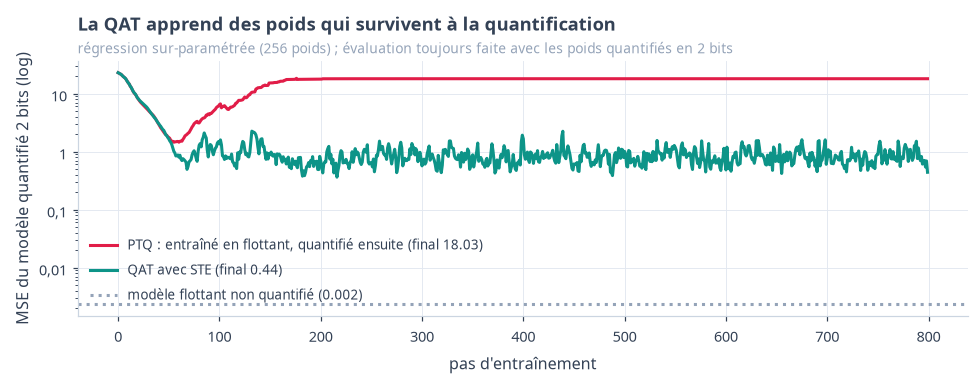

In [23]:
torch.manual_seed(0)
n_s = 2048
X0 = torch.randn(n_s, 64)
w_true = torch.randn(64) * torch.rand(64)
yr = X0 @ w_true + 0.05 * torch.randn(n_s)
Xr = X0 @ (torch.randn(64, 256) / 8)  # 256 caractéristiques redondantes
d_in = Xr.shape[1]


def q2(w):  # absmax 2 bits signé : niveaux -s, 0, s
    s = w.abs().max().clamp(min=1e-8)
    return torch.clamp(torch.round(w / s), -1, 1) * s


def train(qat, steps=800):
    w_ = (0.01 * torch.randn(d_in, generator=torch.Generator().manual_seed(1))).requires_grad_()
    opt = torch.optim.Adam([w_], lr=0.003)
    hist = []
    for _ in range(steps):
        w_eff = w_ + (q2(w_) - w_).detach() if qat else w_  # STE : quantifié en avant, identité en arrière
        loss = ((Xr @ w_eff - yr) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            hist.append(((Xr @ q2(w_) - yr) ** 2).mean().item())
    return w_.detach(), hist


w_ptq, h_ptq = train(False)
w_qat, h_qat = train(True)
mse_float = ((Xr @ w_ptq - yr) ** 2).mean().item()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(h_ptq, color=ROSE, label=f"PTQ : entraîné en flottant, quantifié ensuite (final {h_ptq[-1]:.2f})")
ax.plot(h_qat, color=TEAL, label=f"QAT avec STE (final {h_qat[-1]:.2f})")
ax.axhline(mse_float, color=GRAY, ls=":", label=f"modèle flottant non quantifié ({mse_float:.3f})")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'entraînement"); ax.set_ylabel("MSE du modèle quantifié 2 bits (log)")
ax.legend(fontsize=8.8)
c7.title_sub(ax, "La QAT apprend des poids qui survivent à la quantification",
             "régression sur-paramétrée (256 poids) ; évaluation toujours faite avec les poids quantifiés en 2 bits")
plt.tight_layout(); plt.show()

La PTQ optimise le modèle flottant sans se soucier de l'arrondi, qui intervient ensuite
comme une perturbation subie. La QAT optimise directement le modèle **tel qu'il sera
servi** et trouve, grâce à la redondance des paramètres, une solution bien meilleure parmi
les poids représentables (l'erreur reste au-dessus du modèle flottant : trois niveaux,
c'est très peu). Sans sur-paramétrage (autant de poids que de variables), le gain de la
QAT fond : c'est la redondance des grands réseaux qui la rend efficace. Le livre cite
aussi LLM-QAT (Liu et al., 2023), qui quantifie poids et activations en 4 bits mais garde
les embeddings en 16 bits, et rappelle que l'on peut changer de précision selon la phase :
pré-entraîner en haute précision, finetuner en basse précision (c'est exactement QLoRA,
cours 3).

> **À retenir.** La PTQ est simple et dominante pour l'inférence ; la QAT améliore la
> qualité à très basse précision sans réduire le coût d'entraînement ; l'entraînement en
> précision mixte réduit le coût en gardant une copie haute précision des poids.

## Synthèse

- Un paramètre **entraînable** coûte un poids, un gradient et (avec Adam) deux états ; un
  paramètre gelé ne coûte que son poids. D'où la règle : entraînement complet $\approx$ 4 à
  8 fois la mémoire des poids, plus les **activations**.
- Les formules prévoient exactement poids, gradients et états (mesures sur GPT-2) ; les
  activations, dominées sur les petits modèles par les **logits** d'un grand vocabulaire,
  se mesurent. Le gradient checkpointing les réduit au prix d'une passe avant en plus.
- Les formats flottants arbitrent entre **plage** et **précision** (FP16 contre BF16) ;
  l'entraînement exige de la précision pour les accumulations et les petites mises à jour
  (précision mixte, copie maîtresse FP32).
- La **quantification** des poids (absmax, zéro-point, par groupe, NF4) divise la mémoire
  par 2 à 4 avec une perte faible jusqu'à 4 bits par groupe ; la QAT va plus bas.

Le cours 3 combine ces deux leviers, moins de paramètres entraînables (LoRA) et moins de
bits (QLoRA). Le chapitre 9 reviendra sur la quantification et le cache KV pour
l'inférence.

In [24]:
llm.free_gpu()